# Interactive three-body surface of section

Click a point $(\theta, a_r)$ on the surface of section to launch an orbit from that initial condition. Each click runs

* the **Namouni map** (`NamouniMap` from `testmap.ipynb`), with dots on the section, and
* a **REBOUND N-body** integration (`setup_four` from `testmap.ipynb`), with crosses on the section, plus the paths of the bodies.

The eccentricity for a clicked $a_r$ comes from the conserved quantity $C = K - I$, the same one used for the sections in `testmap.ipynb`. Every orbit therefore lies on the background section.

Panels:
1. **Surface of section.** Grey is the background map section; colours are the clicked orbits.
2. **Test particle relative to the planet.** The path in the frame co-rotating with the planet (planet at the origin). The faint line is the first conjunction; the animation trails the most recent one.
3. **$a_r$ at each conjunction.** Map (solid) vs. N-body (dashed).
4. **Inertial frame.** Star, planet (black) and test particle, animated with a one-orbit trail over the first `Nanim` conjunctions.

Requires `rebound` and `ipympl` (`%matplotlib widget`) in the kernel environment.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import rebound
from scipy.signal import find_peaks
from matplotlib.animation import FuncAnimation
from ipywidgets import Button, HBox, Output
from IPython.display import display

import warnings #to catch warning in implicit update
warnings.simplefilter("error", RuntimeWarning)

## Model (copied from `testmap.ipynb`)
`NamouniMap` is unchanged, except that `runmap` passes `self.ind` to each step instead of the notebook-global `ind`.

In [2]:
class NamouniMap():
    r"""
    A class representing the Namouni map. The map depends on parameters,
    :math:`K`, :math:`\phi`, :math:`\lambda`, and :math:`I`. The map is defined by the equations

    .. math::
        \begin{align}
        I_{n+1} &= I_n + W_\phi(I_{n+1},K_{n+1},\lambda_n,\phi_n) \\
        \phi_{n+1} &= \phi_n + W_\I(I_{n+1},K_{n+1},\lambda_n,\phi_n) \\
        K_{n+1} = I_{n+1}-I_n+K_n \\
        \lambda_{n+1} = \lambda_n + \frac{4\pi}{3\epsilon\sqrt{8K_{n+1}/3}}
        \end{align}


    See also Namouni et al. (1996)

    Parameters
    ----------
    m : float
        Planet-star mass ratio.
    e0 : float
        Initial eccentricity of the test particle
    a_r0 : float
        Initial relative semimajor axis in Hill's unit
    lambda0 : float
        Initial conjunction longitude
    phi0 : float
        Initial pericenter longitude
    ind : int
        An integer that indicates the configuration of the planetary system. 
        If ind == 1, the massive planet comes before the test particle.
        Otherwise, the test particle comes first.
    exact_period : bool, optional
        If True, the update for lambda_{n+1} will be calculated as in Duncan et al. (1989), 
        which is the exact calculation.
        Otherwise, the update will follow the original Namouni mapping which is the approximation in Hill's limit.
        Default is True.
    """

    
    def __init__(self,m,ind,order,exact_period=True):
        self._m = m
        self._ind = ind
        # self._Nmax = Nmax
        # self._y0 = y0
        # self._update_amplitudes()
        # self.mod = mod
        self._order = order
        self.exact_period = exact_period

    @property
    def m(self):
        return self._m

    @property
    def ind(self):
        return self._ind

    @property
    def order(self):
        return self._order
    
    @property
    def epsilon(self):
        m = self._m
        return (m/3)**(1/3) 

    @property
    def exact_period(self):
        return self._exact_period
        
    @exact_period.setter
    def exact_period(self,val):
        self._exact_period = val
        if val:
            self._periodfn = lambda Knp1: 2*np.pi*np.abs(1/((1+np.sqrt(8*Knp1/3)*self.epsilon)**(-3/2)-1))
        else:
            self._periodfn = lambda Knp1: 4*np.pi/(3*self.epsilon*np.sqrt(8*Knp1/3))

    def namouni_fo_step(self, In, Kn, phin, lambdan, arn, ind):
        """First-order Namouni mapping step."""
        
        W101 = 3.359350011
        hn = np.sqrt(2*In)*np.cos(phin)
        kn = np.sqrt(2*In)*np.sin(phin)
        if ind == 1:
            hprime = hn + 2*W101*np.sin(lambdan)/arn**2 # + for Namouni, - for pomega
            kprime = kn - 2*W101*np.cos(lambdan)/arn**2 # - for Namouni, + for pomega
            # hprime = hn + 2*W101*np.sin(lambdan)/arn
            # kprime = kn - 2*W101*np.cos(lambdan)/arn
        else: #from DQT, the sign switches for the outer pair
            hprime = hn - 2*W101*np.sin(lambdan)/arn**2
            kprime = kn + 2*W101*np.cos(lambdan)/arn**2 
            # hprime = hn - 2*W101*np.sin(lambdan)/arn
            # kprime = kn + 2*W101*np.cos(lambdan)/arn
        phiprime = np.arctan2(kprime, hprime) # 4 quadrant arctan
        #print(hn, kn)
        # both options should give the same result:
        Iprime = 1/2*(hprime**2 + kprime**2)
        #Inprime = In + 2*W1/arn**2*np.sqrt(2*In)*np.sin(thetan) + 2*W1**2/arn**4
        #Namouni update
        hnp1 = hprime
        knp1 = kprime
        Inp1 = Iprime
        Knp1 = Kn + (Inp1 - In)
        # Knp1 = Kn + (Inp1 - In)*arn**2
        # print(Knp1)
        phinp1 = phiprime

        lambdanp1 = lambdan + self._periodfn(Knp1)
        # if exact_period==True:
        #     lambdanp1 = lambdan + 2*np.pi*np.abs(1/((1+np.sqrt(8*Knp1/3)*epsilon)**(-3/2)-1)) #same lambda
        # else:
        #     lambdanp1 = lambdan + 4*np.pi/(3*epsilon*np.sqrt(8*Knp1/3))
        return Inp1, Knp1, phinp1, lambdanp1, hnp1, knp1


    def namouni_so_step(self, In, Kn, phin, lambdan, arn, ind):
        """Second-order Namouni mapping step."""
        """The second order mapping involves an intermediate step and implicit scheme for eccentricity update."""
        """This calculates the implicit update iteratively instead of explicitly solving for the next value."""
        W200= -1
        W101= 3.359350011
        W202= -2.678665722        
        hn = np.sqrt(2*In)*np.cos(phin)
        kn = np.sqrt(2*In)*np.sin(phin)
        if ind == 1:
            hprime = hn + 2*W101*np.sin(lambdan)/arn**2 # + for Namouni, - for pomega
            kprime = kn - 2*W101*np.cos(lambdan)/arn**2 # - for Namouni, + for pomega
            # hprime = hn + 2*W101*np.sin(lambdan)/arn
            # kprime = kn - 2*W101*np.cos(lambdan)/arn
        else: #from DQT, the sign switches for the outer pair
            hprime = hn - 2*W101*np.sin(lambdan)/arn**2
            kprime = kn + 2*W101*np.cos(lambdan)/arn**2 
            # hprime = hn - 2*W101*np.sin(lambdan)/arn
            # kprime = kn + 2*W101*np.cos(lambdan)/arn
        phiprime = np.arctan2(kprime, hprime) # 4 quadrant arctan
        #thetaprime = (pomegaprime - lambdan)
        thetaprime = (phiprime - lambdan)
    
        # A = calc_coeff(2, W2, arn, thetaprime)
        # E1 = 1/(1+A)
        # Inp1 = E1*Inprime
        #implicit I update
        Iprime = 0.5*(hprime**2 + kprime**2)
        
        Inp1_prev = Iprime #first guess = Iprime
        while True: #iteratively update using implicit scheme
            Inp1_next = Iprime - 4*W202*np.sin(2*thetaprime)*2*Inp1_prev/arn**3
            # Inp1_next = Iprime - 4*W202*np.sin(2*thetaprime)*2*Inp1_prev/arn #with Istar scale
            if np.abs((Inp1_next-Inp1_prev)/Inp1_next) < 1e-12: #break when satisfied
                break
            Inp1_prev = Inp1_next
        # Inp1 = (0.5*(hprime**2 + kprime**2)) / (1 + 4*W2*np.sin(2*thetaprime)*2/arn**3)
        Inp1 = Inp1_next
    
        #pomeganp1 = pomegaprime - (W200 + 2*W2*np.cos(2*thetaprime))*2/arn**3
        phinp1 = phiprime - (W200 + 2*W202*np.cos(2*thetaprime))*2/arn**3
        Knp1 = Kn + Inp1 - In
        # Knp1 = Kn + (Inp1 - In)*arn**2 #Istar scale
        hnp1 = np.sqrt(2*Inp1)*np.cos(phinp1)
        knp1 = np.sqrt(2*Inp1)*np.sin(phinp1)
        lambdanp1 = lambdan + self._periodfn(Knp1)
        # if exact_period==True:
        #     lambdanp1 = lambdan + 2*np.pi*np.abs(1/((1+np.sqrt(8*Knp1/3)*epsilon)**(-3/2)-1)) #same lambda
        # else:
        #     lambdanp1 = lambdan + 4*np.pi/(3*epsilon*np.sqrt(8*Knp1/3))
        return Inp1, Knp1, phinp1, lambdanp1, hnp1, knp1



    def namouni_4o_step(self, In, Kn, phin, lambdan, arn, ind):
        """Fourth-order Namouni mapping step."""
        """The fourth order mapping involves an intermediate step and implicit scheme for eccentricity update."""
        """This calculates the implicit update iteratively instead of explicitly solving for the next value."""
        W200, W400= -1,-3/8
        W101, W301 = 3.359350011, 0.1430675142
        W202, W402 = -2.678665722, 0.5232506456
        W303 = 2.639498803
        W404 = -2.855951527
        hn = np.sqrt(2*In)*np.cos(phin)
        kn = np.sqrt(2*In)*np.sin(phin)
   
        if ind == 1:
            hprime = hn + 2*W101*np.sin(lambdan)/arn**2 # + for Namouni, - for pomega
            kprime = kn - 2*W101*np.cos(lambdan)/arn**2 # - for Namouni, + for pomega
            # hprime = hn + 2*W101*np.sin(lambdan)/arn
            # kprime = kn - 2*W101*np.cos(lambdan)/arn
        else: #from DQT, the sign switches for the outer pair
            hprime = hn - 2*W101*np.sin(lambdan)/arn**2
            kprime = kn + 2*W101*np.cos(lambdan)/arn**2 
            # hprime = hn - 2*W101*np.sin(lambdan)/arn
            # kprime = kn + 2*W101*np.cos(lambdan)/arn
        phiprime = np.arctan2(kprime, hprime) # 4 quadrant arctan
        #thetaprime = (pomegaprime - lambdan)
        thetaprime = (phiprime - lambdan)
    
        # A = calc_coeff(2, W2, arn, thetaprime)
        # E1 = 1/(1+A)
        # Inp1 = E1*Inprime
        #implicit I update
        Iprime = 0.5*(hprime**2 + kprime**2)
        
        Inp1_prev = Iprime #first guess = Iprime
        phinp1_prev = phiprime
        try:
            while True: #iteratively update using implicit scheme
                Inp1o1 = 2*(W301/arn**4*(2*Inp1_prev)**1.5)*np.sin(thetaprime)
                Inp1o2 = 4*W202*np.sin(2*thetaprime)*2*Inp1_prev/arn**3
                Inp1o3 = (2*W301*np.sin(thetaprime)+6*W303*np.sin(3*thetaprime))*(2*Inp1_prev)**(3/2)/arn**4
                Inp1o4 = (4*W402*np.sin(2*thetaprime)+8*W404*np.sin(4*thetaprime))*(2*Inp1_prev)**(2)/arn**5

                # #Istar scale
                # Inp1o1 = 2*(W301/arn*(2*Inp1_prev)**1.5)*np.sin(thetaprime)
                # Inp1o2 = 4*W202*np.sin(2*thetaprime)*2*Inp1_prev/arn
                # Inp1o3 = (2*W301*np.sin(thetaprime)+6*W303*np.sin(3*thetaprime))*(2*Inp1_prev)**(3/2)/arn
                # Inp1o4 = (4*W402*np.sin(2*thetaprime)+8*W404*np.sin(4*thetaprime))*(2*Inp1_prev)**(2)/arn
                Inp1_next = Iprime - Inp1o1 - Inp1o2 - Inp1o3 - Inp1o4
                
                phinp1o2 = (W200 + 2*W202*np.cos(2*thetaprime))*2/arn**3
                phinp1o3 = 3*2**(3/2)*(W301*np.cos(thetaprime)+W303*np.cos(3*thetaprime))*Inp1_prev**0.5/arn**4
                phinp1o4 = 8*(W400+2*W402*np.cos(2*thetaprime)+2*W404*np.cos(4*thetaprime))*Inp1_prev/arn**5
                # #Istar scale
                # phinp1o2 = (W200 + 2*W202*np.cos(2*thetaprime))*2/arn**3
                # phinp1o3 = 3*2**(3/2)*(W301*np.cos(thetaprime)+W303*np.cos(3*thetaprime))*Inp1_prev**0.5/arn**3
                # phinp1o4 = 8*(W400+2*W402*np.cos(2*thetaprime)+2*W404*np.cos(4*thetaprime))*Inp1_prev/arn**3
                phinp1_next = phiprime - (phinp1o2+phinp1o3+phinp1o4)
                if np.abs((Inp1_next-Inp1_prev)/Inp1_next) < 1e-12 and np.abs((phinp1_next-phinp1_prev)/phinp1_next) < 1e-12: 
                    #break when satisfied
                    break
                Inp1_prev = Inp1_next
                phinp1_prev = phinp1_next
        except RuntimeWarning as e:
            print("Inp1 candidate", Inp1_prev)
            print("Iprime", Iprime)
        Inp1 = Inp1_next
        phinp1 = phinp1_next
        Knp1 = Kn + Inp1 - In
        # Knp1 = Kn + (Inp1 - In)*arn**2 #Istar scale
        hnp1 = np.sqrt(2*Inp1)*np.cos(phinp1)
        knp1 = np.sqrt(2*Inp1)*np.sin(phinp1)
        lambdanp1 = lambdan + self._periodfn(Knp1)
        # if exact_period==True:
        #     lambdanp1 = lambdan + 2*np.pi*np.abs(1/((1+np.sqrt(8*Knp1/3)*epsilon)**(-3/2)-1)) #same lambda
        # else:
        #     lambdanp1 = lambdan + 4*np.pi/(3*epsilon*np.sqrt(8*Knp1/3))
        return Inp1, Knp1, phinp1, lambdanp1, hnp1, knp1

    def namouni_10o_step(self, In, Kn, phin, lambdan, arn, ind):
        """Tenth-order Namouni mapping step."""
        """The tenth order mapping involves an intermediate step and implicit scheme for eccentricity update."""
        """This calculates the implicit update iteratively instead of explicitly solving for the next value."""
        #define all coeffs in here so that we won't get confused
        #format WABC = W^{A,B}_C
        W200, W400, W600, W800, W1000 = -1,-3/8,-5/24,-35/256,-63/640
        W101, W301, W501, W701, W901 = 3.359350011, 0.1430675142, 0.2652528982, 0.1598760057, 0.1125398541
        W202, W402, W602, W802, W1002 = -2.678665722, 0.5232506456, -0.2880525893, -0.1146109541, -0.09264257446
        W303, W503, W703, W903 = 2.639498803, -1.270297850, 0.5079066956, 0.04027194541
        W404, W604, W804, W1004 = -2.855951527, 2.244981532, -1.030263325, 0.1370220235
        W505, W705, W905 = 3.259400253, -3.586274249, 2.034584646
        W606, W806, W1006 = -3.850815349, 5.467708834, -3.807558748
        W707, W907 = 4.661571101, -8.124434579
        W808, W1008 = -5.745863967, 11.88290720
        W909 = 7.181868977
        W10010 = -9.077037610
        hn = np.sqrt(2*In)*np.cos(phin)
        kn = np.sqrt(2*In)*np.sin(phin)
     
        if ind == 1:
            hprime = hn + 2*W101*np.sin(lambdan)/arn**2 # + for Namouni, - for pomega
            kprime = kn - 2*W101*np.cos(lambdan)/arn**2 # - for Namouni, + for pomega
            # hprime = hn + 2*W101*np.sin(lambdan)/arn
            # kprime = kn - 2*W101*np.cos(lambdan)/arn
        else: #from DQT, the sign switches for the outer pair
            hprime = hn - 2*W101*np.sin(lambdan)/arn**2
            kprime = kn + 2*W101*np.cos(lambdan)/arn**2 
            # hprime = hn - 2*W101*np.sin(lambdan)/arn
            # kprime = kn + 2*W101*np.cos(lambdan)/arn
        phiprime = np.arctan2(kprime, hprime) # 4 quadrant arctan
        #thetaprime = (pomegaprime - lambdan)
        thetaprime = (phiprime - lambdan)
    
        
        #implicit I update
        Iprime = 0.5*(hprime**2 + kprime**2)
        
        Inp1_prev = Iprime #first guess = Iprime
        phinp1_prev = phiprime
        try:
            while True: #iteratively update using implicit scheme
                Inp1o1 = 2*(W301/arn**4*(2*Inp1_prev)**1.5+W501/arn**6*(2*Inp1_prev)**2.5+W701/arn**8*(2*Inp1_prev)**3.5+W901/arn**10*(2*Inp1_prev)**4.5)*np.sin(thetaprime)
                Inp1o2 = 4*(W202/arn**3*(2*Inp1_prev)+W402/arn**5*(2*Inp1_prev)**2+W602/arn**7*(2*Inp1_prev)**3+W802/arn**9*(2*Inp1_prev)**4+W1002/arn**11*(2*Inp1_prev)**5)*np.sin(2*thetaprime)
                Inp1o3 = 6*(W303/arn**4*(2*Inp1_prev)**1.5+W503/arn**6*(2*Inp1_prev)**2.5+W703/arn**8*(2*Inp1_prev)**3.5+W903/arn**10*(2*Inp1_prev)**4.5)*np.sin(3*thetaprime)
                Inp1o4 = 8*(W404/arn**5*(2*Inp1_prev)**2+W604/arn**7*(2*Inp1_prev)**3+W804/arn**9*(2*Inp1_prev)**4+W1004/arn**11*(2*Inp1_prev)**5)*np.sin(4*thetaprime)
                Inp1o5 = 10*(W505/arn**6*(2*Inp1_prev)**2.5+W705/arn**8*(2*Inp1_prev)**3.5+W905/arn**10*(2*Inp1_prev)**4.5)*np.sin(5*thetaprime)
                Inp1o6 = 12*(W606/arn**7*(2*Inp1_prev)**3+W806/arn**9*(2*Inp1_prev)**4+W1006/arn**11*(2*Inp1_prev)**5)*np.sin(6*thetaprime)
                Inp1o7 = 14*(W707/arn**8*(2*Inp1_prev)**3.5+W907/arn**10*(2*Inp1_prev)**4.5)*np.sin(7*thetaprime)
                Inp1o8 = 16*(W808/arn**9*(2*Inp1_prev)**4+W1008/arn**11*(2*Inp1_prev)**5)*np.sin(8*thetaprime)
                Inp1o9 = 18*(W909/arn**10*(2*Inp1_prev)**4.5)*np.sin(9*thetaprime)
                Inp1o10 = 20*(W10010/arn**11*(2*Inp1_prev)**5)*np.sin(10*thetaprime)


                # Inp1o1 = 2*(W301*(2*Inp1_prev)**1.5 + W501*(2*Inp1_prev)**2.5 + W701*(2*Inp1_prev)**3.5 + W901*(2*Inp1_prev)**4.5)*np.sin(thetaprime)/arn
                # Inp1o2 = 4*(W202*(2*Inp1_prev) + W402*(2*Inp1_prev)**2 + W602*(2*Inp1_prev)**3 + W802*(2*Inp1_prev)**4 + W1002*(2*Inp1_prev)**5)*np.sin(2*thetaprime)/arn
                # Inp1o3 = 6*(W303*(2*Inp1_prev)**1.5 + W503*(2*Inp1_prev)**2.5 + W703*(2*Inp1_prev)**3.5 + W903*(2*Inp1_prev)**4.5)*np.sin(3*thetaprime)/arn
                # Inp1o4 = 8*(W404*(2*Inp1_prev)**2 + W604*(2*Inp1_prev)**3 + W804*(2*Inp1_prev)**4 + W1004*(2*Inp1_prev)**5)*np.sin(4*thetaprime)/arn
                # Inp1o5 = 10*(W505*(2*Inp1_prev)**2.5 + W705*(2*Inp1_prev)**3.5 + W905*(2*Inp1_prev)**4.5)*np.sin(5*thetaprime)/arn
                # Inp1o6 = 12*(W606*(2*Inp1_prev)**3 + W806*(2*Inp1_prev)**4 + W1006*(2*Inp1_prev)**5)*np.sin(6*thetaprime)/arn
                # Inp1o7 = 14*(W707*(2*Inp1_prev)**3.5 + W907*(2*Inp1_prev)**4.5)*np.sin(7*thetaprime)/arn
                # Inp1o8 = 16*(W808*(2*Inp1_prev)**4 + W1008*(2*Inp1_prev)**5)*np.sin(8*thetaprime)/arn
                # Inp1o9 = 18*(W909*(2*Inp1_prev)**4.5)*np.sin(9*thetaprime)/arn
                # Inp1o10 = 20*(W10010*(2*Inp1_prev)**5)*np.sin(10*thetaprime)/arn                
        
                Inp1_next = Iprime-Inp1o1-Inp1o2-Inp1o3-Inp1o4-Inp1o5-Inp1o6-Inp1o7-Inp1o8-Inp1o9-Inp1o10
                
                phinp1o0 = W200*2/arn**3+W400*2**2*2*Inp1_prev/arn**5+W600*2**3*3*Inp1_prev**2/arn**7+W800*2**4*4*Inp1_prev**3/arn**9+W1000*2**5*5*Inp1_prev**4/arn**11
                phinp1o1 = 2*(W301*2**1.5*1.5*Inp1_prev**0.5/arn**4+W501*2**2.5*2.5*Inp1_prev**1.5/arn**6+W701*2**3.5*3.5*Inp1_prev**2.5/arn**8+W901*2**4.5*4.5*Inp1_prev**3.5/arn**10)*np.cos(thetaprime)
                phinp1o2 = 2*(W202*2/arn**3+W402*2**2*2*Inp1_prev/arn**5+W602*2**3*3*Inp1_prev**2/arn**7+W802*2**4*4*Inp1_prev**3/arn**9+W1002*2**5*5*Inp1_prev**4/arn**11)*np.cos(2*thetaprime)
                phinp1o3 = 2*(W303*2**1.5*1.5*Inp1_prev**0.5/arn**4+W503*2**2.5*2.5*Inp1_prev**1.5/arn**6+W703*2**3.5*3.5*Inp1_prev**2.5/arn**8+W903*2**4.5*4.5*Inp1_prev**3.5/arn**10)*np.cos(3*thetaprime)
                phinp1o4 = 2*(W404*2**2*2*Inp1_prev/arn**5+W604*2**3*3*Inp1_prev**2/arn**7+W804*2**4*4*Inp1_prev**3/arn**9+W1004*2**5*5*Inp1_prev**4/arn**11)*np.cos(4*thetaprime)
                phinp1o5 = 2*(W505*2**2.5*2.5*Inp1_prev**1.5/arn**6+W705*2**3.5*3.5*Inp1_prev**2.5/arn**8+W905*2**4.5*4.5*Inp1_prev**3.5/arn**10)*np.cos(5*thetaprime)
                phinp1o6 = 2*(W606*2**3*3*Inp1_prev**2/arn**7+W806*2**4*4*Inp1_prev**3/arn**9+W1006*2**5*5*Inp1_prev**4/arn**11)*np.cos(6*thetaprime)
                phinp1o7 = 2*(W707*2**3.5*3.5*Inp1_prev**2.5/arn**8+W907*2**4.5*4.5*Inp1_prev**3.5/arn**10)*np.cos(7*thetaprime)
                phinp1o8 = 2*(W808*2**4*4*Inp1_prev**3/arn**9+W1008*2**5*5*Inp1_prev**4/arn**11)*np.cos(8*thetaprime)
                phinp1o9 = 2*(W909*2**4.5*4.5*Inp1_prev**3.5/arn**10)*np.cos(9*thetaprime)
                phinp1o10 = 2*(W10010*2**5*5*Inp1_prev**4/arn**11)*np.cos(10*thetaprime)

                # phinp1o0 = (W200*2 + W400*2**2*2*Inp1_prev + W600*2**3*3*Inp1_prev**2 + W800*2**4*4*Inp1_prev**3 + W1000*2**5*5*Inp1_prev**4)/arn**3
                # phinp1o1 = 2*(W301*2**1.5*1.5*Inp1_prev**0.5 + W501*2**2.5*2.5*Inp1_prev**1.5 + W701*2**3.5*3.5*Inp1_prev**2.5 + W901*2**4.5*4.5*Inp1_prev**3.5)*np.cos(thetaprime)/arn**3
                # phinp1o2 = 2*(W202*2 + W402*2**2*2*Inp1_prev + W602*2**3*3*Inp1_prev**2 + W802*2**4*4*Inp1_prev**3 + W1002*2**5*5*Inp1_prev**4)*np.cos(2*thetaprime)/arn**3
                # phinp1o3 = 2*(W303*2**1.5*1.5*Inp1_prev**0.5 + W503*2**2.5*2.5*Inp1_prev**1.5 + W703*2**3.5*3.5*Inp1_prev**2.5 + W903*2**4.5*4.5*Inp1_prev**3.5)*np.cos(3*thetaprime)/arn**3
                # phinp1o4 = 2*(W404*2**2*2*Inp1_prev + W604*2**3*3*Inp1_prev**2 + W804*2**4*4*Inp1_prev**3 + W1004*2**5*5*Inp1_prev**4)*np.cos(4*thetaprime)/arn**3
                # phinp1o5 = 2*(W505*2**2.5*2.5*Inp1_prev**1.5 + W705*2**3.5*3.5*Inp1_prev**2.5 + W905*2**4.5*4.5*Inp1_prev**3.5)*np.cos(5*thetaprime)/arn**3
                # phinp1o6 = 2*(W606*2**3*3*Inp1_prev**2 + W806*2**4*4*Inp1_prev**3 + W1006*2**5*5*Inp1_prev**4)*np.cos(6*thetaprime)/arn**3
                # phinp1o7 = 2*(W707*2**3.5*3.5*Inp1_prev**2.5 + W907*2**4.5*4.5*Inp1_prev**3.5)*np.cos(7*thetaprime)/arn**3
                # phinp1o8 = 2*(W808*2**4*4*Inp1_prev**3 + W1008*2**5*5*Inp1_prev**4)*np.cos(8*thetaprime)/arn**3
                # phinp1o9 = 2*(W909*2**4.5*4.5*Inp1_prev**3.5)*np.cos(9*thetaprime)/arn**3
                # phinp1o10 = 2*(W10010*2**5*5*Inp1_prev**4)*np.cos(10*thetaprime)/arn**3
                phinp1_next = phiprime-phinp1o0-phinp1o1-phinp1o2-phinp1o3-phinp1o4-phinp1o5-phinp1o6-phinp1o7-phinp1o8-phinp1o9-phinp1o10
                if np.abs((Inp1_next-Inp1_prev)/Inp1_next) < 1e-12 and np.abs((phinp1_next-phinp1_prev)/phinp1_next) < 1e-12: 
                    #break when satisfied
                    break
                Inp1_prev = Inp1_next
                phinp1_prev = phinp1_next
    
        except RuntimeWarning as e:
            print("Inp1 candidate", Inp1_prev)
            print("Iprime", Iprime)
                
            
            
        Inp1 = Inp1_next
        phinp1 = phinp1_next
        Knp1 = Kn + Inp1 - In
        # Knp1 = Kn + (Inp1 - In)*arn**2 #Istar scale
        hnp1 = np.sqrt(2*Inp1)*np.cos(phinp1)
        knp1 = np.sqrt(2*Inp1)*np.sin(phinp1)
        lambdanp1 = lambdan + self._periodfn(Knp1)
        # if exact_period==True:
        #     lambdanp1 = lambdan + 2*np.pi*np.abs(1/((1+np.sqrt(8*Knp1/3)*epsilon)**(-3/2)-1)) #same lambda
        # else:
        #     lambdanp1 = lambdan + 4*np.pi/(3*epsilon*np.sqrt(8*Knp1/3))
        return Inp1, Knp1, phinp1, lambdanp1, hnp1, knp1

        #This function runs Namouni mapping for multiple conjunctions
    def runmap(self, I0, K0, phi0, lambda0, Nconj, order):
        try:                # minimize function later passes a 1-element list, so make it work for both scalar and list
            K0 = K0[0]
        except:
            pass
        Is, Ks, phis, lambdas, hs, ks = np.zeros(Nconj+1), np.zeros(Nconj+1), np.zeros(Nconj+1), np.zeros(Nconj+1), np.zeros(Nconj+1), np.zeros(Nconj+1)
        Is[0] = I0
        Ks[0] = K0
        phis[0] = phi0
        lambdas[0] = lambda0
        ar0 = np.sqrt(8*K0/3)
        for i in range(Nconj):
            if order==1:
                Is[i+1], Ks[i+1], phis[i+1], lambdas[i+1], hs[i+1], ks[i+1] = self.namouni_fo_step(Is[i], Ks[i], phis[i], lambdas[i], ar0, self.ind)
            elif order==2:
                Is[i+1], Ks[i+1], phis[i+1], lambdas[i+1], hs[i+1], ks[i+1] = self.namouni_so_step(Is[i], Ks[i], phis[i], lambdas[i], ar0, self.ind)
            elif order==4:
                Is[i+1], Ks[i+1], phis[i+1], lambdas[i+1], hs[i+1], ks[i+1] = self.namouni_4o_step(Is[i], Ks[i], phis[i], lambdas[i], ar0, self.ind)
            elif order==10:
                Is[i+1], Ks[i+1], phis[i+1], lambdas[i+1], hs[i+1], ks[i+1] = self.namouni_10o_step(Is[i], Ks[i], phis[i], lambdas[i], ar0, self.ind)

        return Is, Ks, phis, lambdas, hs, ks
    
    def __call__(self,X,Nconj,order):
        epsilon = self.epsilon
        e0, a_r0, phi0, lambda0 = X
        I0 = (e0/epsilon)**2/2
        K0 = 3/8*a_r0**2
    
        Is, Ks, phis, lambdas, hs, ks = self.runmap(I0, K0, phi0, lambda0, Nconj, order)
        return Is, Ks, phis, lambdas, hs, ks

In [3]:
def setup_four(a1, a2, mutot, ecc, pomega2, lambda_target, ind, iterations = 0):
    #setup for planets not in exact resonance - takes in noninteger values of period ratio
    if ind == 1:
        ap = a1
        a = a2
    else:
        ap = a2
        a = a1
    ecross = (a-ap)/ap
    Pratio = (a2/a1)**1.5
    n1 = 2*np.pi
    n2 = n1/Pratio
    tconj = 2*np.pi/(n1-n2) # estimate for time between conjunctions
    t0 = -0.8*tconj

    lambda10 = lambda_target+n1*t0 # this should be exact since 
    lambda20 = lambda_target+n2*t0

    setupSim=rebound.Simulation()
    setupSim.add(m=1)
    
    if ind == 1:
        setupSim.add(a=a2, e=ecc, pomega=pomega2, l=lambda_target)
        x_target = setupSim.particles[1].x
    else:
        setupSim.add(a=a1, e=ecc, pomega=pomega2, l=lambda_target)
        x_target = setupSim.particles[1].x

    if ind == 1: #inner pair
        lambda_20_prev = lambda20 # initial guess
        correction = 0
        for i in range(iterations):
            lambda_20 = lambda_20_prev + correction
            sim = rebound.Simulation()
            sim.add(m=1)
            sim.add(primary=sim.particles[0], m=mutot, a=a1, l=lambda10)
            sim.add(primary=sim.particles[0], a=a2, e=ecc, pomega=pomega2, l=lambda_20)
            var_l = sim.add_variation()
            var_l.vary(2, 'l') # how does everything depend on the initial l of particles[2]
            sim.t = t0
            ps = sim.particles
            
            sim.integrate(0)
            correction = (x_target - ps[2].x)/var_l.particles[2].x
            lambda_20_prev = lambda_20
            #print('***',i,'***')
            #print(lambda_20_prev, ps[2].l, lambda_target-ps[2].l, correction)
        
       
        lambda_20 = lambda_20_prev + correction
        sim = rebound.Simulation()
        sim.add(m=1)
        sim.add(primary=sim.particles[0], m=mutot, a=a1, l=lambda10)
        sim.add(primary=sim.particles[0], a=a2, e=ecc, pomega=pomega2, l=lambda_20)
    else: #outer pair
        lambda_10_prev = lambda10 # initial guess
        correction = 0
        for i in range(iterations):
            lambda_10 = lambda_10_prev + correction
            sim = rebound.Simulation()
            sim.add(m=1)
            sim.add(primary=sim.particles[0],a=a1,e=ecc, pomega=pomega2, l=lambda_10)
            sim.add(primary=sim.particles[0],m=mutot, a=a2, l=lambda20)
            var_l = sim.add_variation()
            var_l.vary(1, 'l') # how does everything depend on the initial l of particles[2]
            sim.t = t0
            ps = sim.particles
        
            sim.integrate(0)
            correction = (x_target - ps[1].x)/var_l.particles[1].x
            lambda_10_prev = lambda_10
            #print('***',i,'***')
            #print(lambda_10_prev, ps[2].l, lambda_target-ps[2].l, correction)
        
       
        lambda_10 = lambda_10_prev + correction
        sim = rebound.Simulation()
        sim.add(m=1)
        sim.add(primary=sim.particles[0], a=a1,e=ecc, pomega=pomega2, l=lambda_10)
        sim.add(primary=sim.particles[0], m=mutot, a=a2, l=lambda20)
    sim.t = t0
    return sim

In [4]:
def unwrap_l(ps):
    ''' given a sim.particles object ps, returns relative lambda (l) value of the planets
        removing the 2*pi discontinuities that result when one planet has crossed l=0 but
        the other has not
    '''
    if ps[2].l - ps[1].l > np.pi:
        return ps[2].l - ps[1].l - 2*np.pi
    elif ps[2].l - ps[1].l < -np.pi:
        return ps[2].l - ps[1].l + 2*np.pi
    else:
        return ps[2].l - ps[1].l

## Parameters
These match the 10:9 panel of the four-section plot in `testmap.ipynb`. For the 3:2 case, set `J = 3`.

In [5]:
epsilon = (1e-6/3)**(1/3)   # Hill radius scale
mutot = 3*epsilon**3        # planet-star mass ratio
J = 10                      # J:J-1 resonance sets the centre of the a_r range
ind = 1                     # 1: massive planet inside the test particle (the only case handled below)
order = 10                  # Namouni map order (1, 2, 4 or 10)

a1 = 1
a2 = (J/(J-1))**(2/3)*a1
ecross = (a2-a1)/a1
ar_res = ecross/epsilon     # a_r at exact resonance, in Hill units
ecc = 3*epsilon             # eccentricity at the bottom of the a_r range

# a_r window of the section, and the conserved quantity C = K - I that sets the
# eccentricity for each a_r (I_list = K0_list - C in testmap)
x0_arr = np.linspace(0, 0.25, 40)
ar0_list = (1+x0_arr)*ar_res
C = 3/8*ar0_list[0]**2 - (ecc/epsilon)**2/2

Nconj_bg = 500              # conjunctions per background orbit
Nconj = 200                 # conjunctions per clicked orbit
samples_per_conj = 100      # N-body output points per conjunction (for the section)
Nanim = 20                  # conjunctions sampled finely and animated
samples_per_orbit = 60      # output points per planet orbit during the animated part
print(f"a_r range: {ar0_list[0]:.2f} - {ar0_list[-1]:.2f} Hill units")

a_r range: 10.49 - 13.12 Hill units


## Running one orbit from a clicked $(\theta, a_r)$
The map uses $\theta = \phi - \lambda$. For the N-body section, $\theta = \varpi_2 - \lambda_{conj} + \pi$. This is the same angle; testmap's N-body panels plot $\lambda_{conj} - \varpi_2$ on $[0, 2\pi)$, which runs in the opposite direction. With $\theta_0 = 0$, the setup is testmap's default ($\varpi_2 = 0$, conjunction at $\lambda = \pi$).

In [6]:
def eccentricity_for(ar0):
    """Eccentricity on the section's C = K - I surface, or None if a_r is below it."""
    I0 = 3/8*ar0**2 - C
    return np.sqrt(2*I0)*epsilon if I0 > 0 else None


def run_namouni(theta0, ar0, Nconj):
    """Namouni map from (theta0, ar0). Returns conjunction number, theta_n, a_r,n."""
    n_map = NamouniMap(mutot, ind, order)
    # theta = phi - lambda, so start at lambda0 = 0, phi0 = theta0
    Is, Ks, phis, lambdas, hs, ks = n_map((eccentricity_for(ar0), ar0, theta0, 0.0), Nconj, order)
    thetas = (phis - lambdas + np.pi) % (2*np.pi) - np.pi
    return np.arange(Nconj+1), thetas, np.sqrt(8/3*Ks)


def run_nbody(theta0, ar0, Nconj):
    """
    REBOUND run from (theta0, ar0), using setup_four with the conjunction placed so
    the section starts at theta0. Samples the heliocentric positions (finely for the first
    Nanim conjunctions, which get animated) and picks out section points as new_run does:
    lambda at conjunctions, a_r and pomega halfway between.
    """
    a2_0 = a1 + a1*ar0*epsilon
    lambda_target = (np.pi - theta0) % (2*np.pi)
    sim = setup_four(a1, a2_0, mutot, eccentricity_for(ar0), 0.0, lambda_target, ind)
    ps = sim.particles

    tconj = 2*np.pi/(ps[1].n - ps[2].n)
    orbits_per_conj = tconj*ps[1].n/(2*np.pi)   # planet orbits between conjunctions
    n_fine = int(Nanim*orbits_per_conj*samples_per_orbit)
    times = sim.t + np.concatenate([
        np.linspace(0, Nanim*tconj, n_fine, endpoint=False),
        np.linspace(Nanim*tconj, (Nconj + 0.8)*tconj, (Nconj - Nanim)*samples_per_conj)])
    Nout = len(times)
    xy = np.zeros((Nout, 3, 2))   # star, planet, particle: heliocentric (x, y)
    a12, l12, l2, pomega2 = np.zeros(Nout), np.zeros(Nout), np.zeros(Nout), np.zeros(Nout)
    for i, t in enumerate(times):
        sim.integrate(t)
        for k in (1, 2):
            xy[i, k] = ps[k].x - ps[0].x, ps[k].y - ps[0].y
        a12[i] = (ps[2].a - ps[1].a)/ps[1].a
        l12[i] = unwrap_l(ps)
        l2[i] = ps[2].l
        pomega2[i] = ps[2].pomega

    conj_idx, _ = find_peaks(-np.abs(l12))
    btwn_idx, _ = find_peaks(np.abs(l12))
    n = min(len(conj_idx), len(btwn_idx))
    theta_sec = (pomega2[btwn_idx[:n]] - l2[conj_idx[:n]] + 2*np.pi) % (2*np.pi) - np.pi
    ar_sec = a12[btwn_idx[:n]]/epsilon
    return xy[:n_fine], theta_sec, ar_sec, orbits_per_conj


def rotating_frame(xy):
    """Test particle relative to the planet: azimuth difference and radial offset in Hill units."""
    phi_p = np.arctan2(xy[:, 1, 1], xy[:, 1, 0])
    phi_t = np.arctan2(xy[:, 2, 1], xy[:, 2, 0])
    r_p = np.hypot(xy[:, 1, 0], xy[:, 1, 1])
    r_t = np.hypot(xy[:, 2, 0], xy[:, 2, 1])
    dphi = (phi_t - phi_p + np.pi) % (2*np.pi) - np.pi
    return dphi, (r_t - r_p)/(r_p*epsilon)


def break_wraps(x, y):
    """Insert NaNs where x jumps across +-pi so line plots don't draw horizontal streaks."""
    jumps = np.where(np.abs(np.diff(x)) > np.pi)[0] + 1
    return np.insert(x, jumps, np.nan), np.insert(y, jumps, np.nan)

## Background section

In [7]:
%%time
theta_bg = np.zeros((len(ar0_list), Nconj_bg+1))
ar_bg = np.zeros((len(ar0_list), Nconj_bg+1))
for i, ar in enumerate(ar0_list):
    _, theta_bg[i], ar_bg[i] = run_namouni(0.0, ar, Nconj_bg)

CPU times: user 1.26 s, sys: 10.2 ms, total: 1.27 s
Wall time: 1.28 s


## Interactive plot

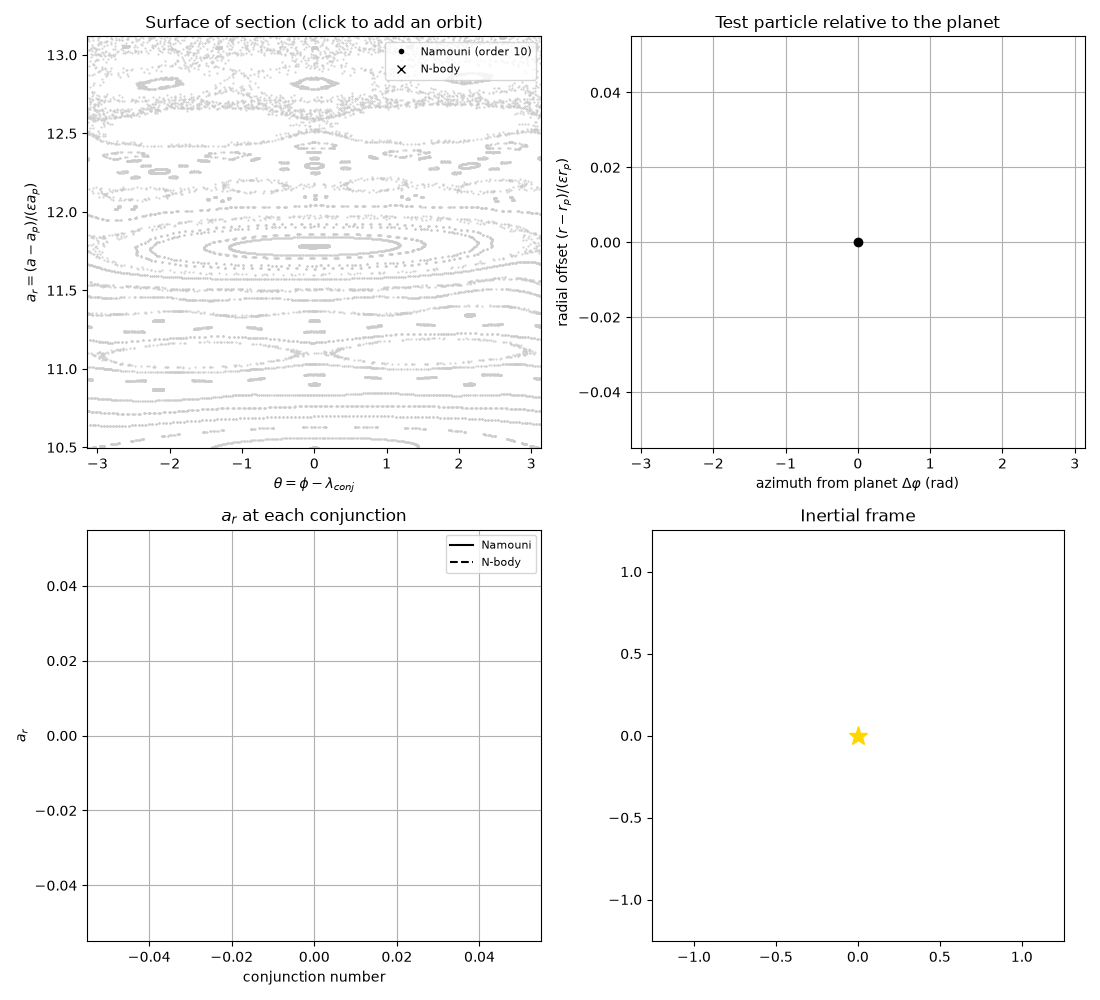

Output()

In [8]:
%matplotlib widget
fig, ((ax_sec, ax_rot), (ax_ar, ax_xy)) = plt.subplots(2, 2, figsize=(11, 10))

# surface of section
ax_sec.set_title("Surface of section (click to add an orbit)")
ax_sec.set_xlabel(r"$\theta = \phi - \lambda_{conj}$")
ax_sec.set_ylabel(r"$a_r = (a - a_p)/(\epsilon a_p)$")
ax_sec.plot(theta_bg.T, ar_bg.T, '.', color='0.8', markersize=1, rasterized=True)
ax_sec.set_xlim(-np.pi, np.pi)
ax_sec.set_ylim(ar0_list[0], ar0_list[-1])
ax_sec.plot([], [], '.', color='k', label=f'Namouni (order {order})')
ax_sec.plot([], [], 'x', color='k', label='N-body')
ax_sec.legend(loc='upper right', fontsize=8)

# co-rotating frame
ax_rot.set_title("Test particle relative to the planet")
ax_rot.set_xlabel(r"azimuth from planet $\Delta\varphi$ (rad)")
ax_rot.set_ylabel(r"radial offset $(r - r_p)/(\epsilon r_p)$")
ax_rot.set_xlim(-np.pi, np.pi)
ax_rot.plot(0, 0, 'ko', markersize=6)
ax_rot.grid(True)

# a_r at each conjunction
ax_ar.set_title(r"$a_r$ at each conjunction")
ax_ar.set_xlabel("conjunction number")
ax_ar.set_ylabel(r"$a_r$")
ax_ar.plot([], [], '-', color='k', label='Namouni')
ax_ar.plot([], [], '--', color='k', label='N-body')
ax_ar.legend(loc='upper right', fontsize=8)
ax_ar.grid(True)

# inertial frame
ax_xy.set_title("Inertial frame")
ax_xy.set_aspect('equal')
lim = 1.15*a2*(1 + 0.25*ecross)
ax_xy.set_xlim(-lim, lim)
ax_xy.set_ylim(-lim, lim)
ax_xy.plot(0, 0, '*', color='gold', markersize=14)

plt.tight_layout()

# ======================
# State containers
# ======================
orbits = []     # static artists for each clicked orbit
current_animation = {"ani": None, "artists": []}
out = Output()

def stop_current_animation():
    ani = current_animation["ani"]
    if ani is not None:
        try:
            ani.event_source.stop()
        except Exception:
            pass
    for art in current_animation["artists"]:
        try:
            art.remove()
        except Exception:
            pass
    current_animation["ani"] = None
    current_animation["artists"] = []
    fig.canvas.draw_idle()

def animate_orbit(xy, dphi, dr, trail, rot_trail, color, frame_step=2):
    """Planet and test particle moving in the inertial frame, and the particle in the co-rotating frame."""
    stop_current_animation()
    planet_dot, = ax_xy.plot([], [], 'o', color='k', markersize=6)
    particle_dot, = ax_xy.plot([], [], 'o', color=color, markersize=5)
    planet_trail, = ax_xy.plot([], [], '-', color='k', lw=0.8, alpha=0.5)
    particle_trail, = ax_xy.plot([], [], '-', color=color, lw=0.8)
    rot_trail_line, = ax_rot.plot([], [], '-', color=color, lw=1.2)
    rot_dot, = ax_rot.plot([], [], 'o', color=color, markersize=7, markeredgecolor='k')
    artists = (planet_dot, particle_dot, planet_trail, particle_trail, rot_trail_line, rot_dot)
    current_animation["artists"] = list(artists)

    def update(i):
        lo = max(0, i - trail)
        planet_dot.set_data([xy[i, 1, 0]], [xy[i, 1, 1]])
        particle_dot.set_data([xy[i, 2, 0]], [xy[i, 2, 1]])
        planet_trail.set_data(xy[lo:i+1, 1, 0], xy[lo:i+1, 1, 1])
        particle_trail.set_data(xy[lo:i+1, 2, 0], xy[lo:i+1, 2, 1])
        lo_rot = max(0, i - rot_trail)
        rot_trail_line.set_data(*break_wraps(dphi[lo_rot:i+1], dr[lo_rot:i+1]))
        rot_dot.set_data([dphi[i]], [dr[i]])
        return artists

    ani = FuncAnimation(fig, update, frames=range(0, len(dphi), frame_step),
                        interval=20, blit=True, repeat=False)
    current_animation["ani"] = ani
    return ani

# ======================
# Click handler
# ======================
def on_click(event):
    if event.inaxes != ax_sec or event.xdata is None:
        return
    theta0, ar0 = float(event.xdata), float(event.ydata)
    with out:
        if eccentricity_for(ar0) is None:
            print(f"a_r = {ar0:.3f} is below the section's C = K - I surface; click higher.")
            return
        color = plt.cm.tab10.colors[len(orbits) % 10]
        artists = []

        try:
            n, theta_map, ar_map = run_namouni(theta0, ar0, Nconj)
        except RuntimeWarning as e:
            print(f"Namouni map failed from theta={theta0:.3f}, a_r={ar0:.3f}: {e}")
            return
        artists += ax_sec.plot(theta_map, ar_map, '.', color=color, markersize=2)
        artists += ax_ar.plot(n, ar_map, '-', color=color, lw=1)

        xy, theta_nb, ar_nb, orbits_per_conj = run_nbody(theta0, ar0, Nconj)
        artists += ax_sec.plot(theta_nb, ar_nb, 'x', color=color, markersize=3, mew=0.6)
        artists += ax_ar.plot(np.arange(len(ar_nb)), ar_nb, '--', color=color, lw=1)

        # static path: the first conjunction; the animation trails the most recent one
        dphi, dr = rotating_frame(xy)
        rot_trail = int(orbits_per_conj*samples_per_orbit)
        artists += ax_rot.plot(*break_wraps(dphi[:rot_trail], dr[:rot_trail]), '-', color=color, lw=0.6, alpha=0.4)
        ax_rot.relim(); ax_rot.autoscale_view(scalex=False)
        ax_ar.relim(); ax_ar.autoscale_view()
        orbits.append(artists)
        fig.canvas.draw_idle()

        animate_orbit(xy, dphi, dr, trail=samples_per_orbit, rot_trail=rot_trail, color=color)
        print(f"Orbit {len(orbits)}: theta0={theta0:.3f}, a_r0={ar0:.3f}, e0={eccentricity_for(ar0)/epsilon:.2f} Hill")

cid = fig.canvas.mpl_connect('button_press_event', on_click)

# ======================
# Clear button
# ======================
clear_btn = Button(description="Clear", button_style="danger")
def clear_all(b=None):
    stop_current_animation()
    for artists in orbits:
        for art in artists:
            try:
                art.remove()
            except Exception:
                pass
    orbits.clear()
    fig.canvas.draw_idle()
    with out:
        out.clear_output()
        print("Cleared orbits.")
clear_btn.on_click(clear_all)

plt.show()
display(HBox([clear_btn]), out)